# 03 - Newton-Raphson: speed versus risk

**Goal.** Implement Newton-Raphson, measure its convergence order, and see how it fails.

**Problem A.** The state-of-charge inversion from notebook 01, now with the analytic derivative

$$\frac{d\,\mathrm{OCV}}{dz} = 1.0 + 0.4\,z + 12\,e^{-30 z}.$$

**Problem B.** A function where Newton's method is guaranteed to fail, $f(x) = \sqrt[3]{x}$.

In [1]:
import sys
sys.path.insert(0, "../src")  # lets this notebook run without installing the package

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (6.5, 3.6), "axes.grid": True})
from nummeth import bisection, newton_raphson, secant

In [2]:
V_MEAS = 3.85

def f(z):
    return 3.0 + 1.0 * z + 0.2 * z**2 - 0.4 * np.exp(-30.0 * z) - V_MEAS

def df(z):
    return 1.0 + 0.4 * z + 12.0 * np.exp(-30.0 * z)

newton = newton_raphson(f, df, x0=0.5, tol=1e-14)
secnt = secant(f, 0.4, 0.6, tol=1e-14)
bisec = bisection(f, 0.0, 1.0, tol=1e-14)

for r in (bisec, secnt, newton):
    print(f"{r.method:>15}: root = {r.root:.12f}, iterations = {r.iterations:>2}, |f| = {r.residual:.1e}")

      bisection: root = 0.740370349274, iterations = 47, |f| = 8.4e-15
         secant: root = 0.740370349274, iterations =  5, |f| = 0.0e+00
 newton-raphson: root = 0.740370349274, iterations =  4, |f| = 0.0e+00


## Convergence order

If the error behaves like $e_{k+1} \approx C\,e_k^{\,p}$, then $p \approx \ln(e_{k+1}/e_k) / \ln(e_k/e_{k-1})$. Newton's method should show $p \approx 2$ near a simple root. Estimates built from errors near machine precision (about $10^{-16}$) are dominated by rounding and are unreliable.

Newton errors : ['2.4e-01', '9.6e-03', '1.4e-05', '3.1e-11']
Newton orders : ['2.02', '2.00']
secant errors : ['3.4e-01', '1.4e-01', '8.0e-03', '1.8e-04', '2.2e-07', '5.9e-12', '3.3e-16']
secant orders : ['3.24', '1.33', '1.76', '1.57', '0.93']


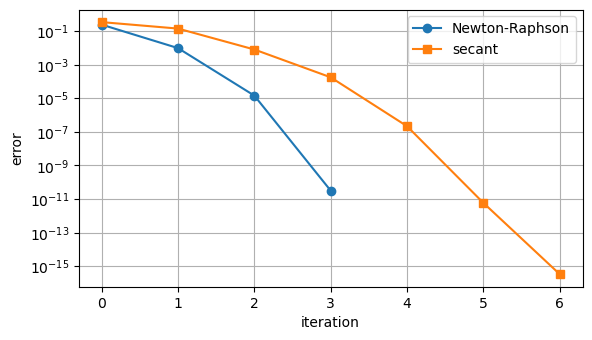

In [3]:
ref = newton.root
def errors(result):
    return [abs(x - ref) for x in result.history if abs(x - ref) > 0]

def orders(e):
    return [np.log(e[k + 1] / e[k]) / np.log(e[k] / e[k - 1]) for k in range(1, len(e) - 1)]

e_newton, e_secant = errors(newton), errors(secnt)
print("Newton errors :", [f"{e:.1e}" for e in e_newton])
print("Newton orders :", [f"{p:.2f}" for p in orders(e_newton)])
print("secant errors :", [f"{e:.1e}" for e in e_secant])
print("secant orders :", [f"{p:.2f}" for p in orders(e_secant)])

plt.semilogy(e_newton, "o-", label="Newton-Raphson")
plt.semilogy(e_secant, "s-", label="secant")
plt.xlabel("iteration"); plt.ylabel("error"); plt.legend(); plt.show()

## A failure: the cube root

For $f(x) = \sqrt[3]{x}$ the Newton update simplifies to $x_{k+1} = -2 x_k$, so the iterates move *away* from the root at $x = 0$ from any nonzero start.

In [4]:
def cbrt(x):
    return np.copysign(np.abs(x) ** (1 / 3), x)

def dcbrt(x):
    return (1 / 3) * np.abs(x) ** (-2 / 3)

bad = newton_raphson(cbrt, dcbrt, 1.0, max_iter=12)
print("iterates:", [f"{x:.0f}" for x in bad.history])
print("converged:", bad.converged)

iterates: ['1', '-2', '4', '-8', '16', '-32', '64', '-128', '256', '-512', '1024', '-2048', '4096']
converged: False


In [5]:
# Another failure: a zero derivative at the starting point.
try:
    newton_raphson(lambda x: x * x - 2, lambda x: 2 * x, 0.0)
except ZeroDivisionError as err:
    print("ZeroDivisionError:", err)

ZeroDivisionError: zero derivative at x = 0.0


## Observations

- What order of convergence did you measure for Newton and for secant? Does it match theory?
- Newton needed fewer iterations than secant, but is it always the better choice? Use the failures above.
- If you had to pick a method for the SOC inversion in a battery management system, which would you choose and why?

Newton's measured order of convergence was about 2.02 and 2.00, which matches the theory (quadratic). The secant orders were noisy (3.24, 1.33, 1.76, 1.57, 0.93); theory says about 1.618 (superlinear). The last value is unreliable because the error is near machine precision (about 1e-16), where rounding dominates.

Newton-Raphson is similar to the secant method, but it uses the derivative f'(x) in place of the secant slope: x_{n+1} = x_n - f(x_n)/f'(x_n). It fails when f'(x) = 0 at an iterate, as in the ZeroDivisionError at x0 = 0 for f = x^2 - 2. It can also fail with a nonzero derivative: for f(x) = cbrt(x) each step gives x_{n+1} = -2 x_n, so the iterates double and alternate in sign (1, -2, 4, -8, ...) and never converge. If the derivative is a nonzero constant, f is linear and Newton converges in one step. So Newton is the best choice when speed matters and the starting point is good, bisection is the safest, and secant sits in the middle and needs no derivative.

For the SOC inversion, f'(z) = 1 + 0.4z + 12e^(-30z) is above 1 for every z, so Newton is safe and fast for this model. In a real battery management system the OCV curve is a measured table, and some chemistries have flat plateaus where the derivative is close to zero, which makes Newton risky; real-time code also wants a bounded iteration count. I would use bisection (it needs only a bracket and has a known worst-case number of iterations) or a hybrid that uses secant or Newton with a bisection fallback. A good starting guess helps secant and Newton, but bisection does not need one, only a bracket.